## 1. Runtime and GPU configuration

In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32  # Global batch size, not per GPU
MAX_EPOCHS = 80
LEARNING_RATE = 1e-3
OUTPUT_DIR = Path('/kaggle/working/lisa_paddy_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)
physical_gpus = tf.config.list_physical_devices('GPU')
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
strategy = tf.distribute.MirroredStrategy() if physical_gpus else tf.distribute.get_strategy()
print('TensorFlow:', tf.__version__)
print('GPUs:', physical_gpus)
print('Synchronous replicas:', strategy.num_replicas_in_sync)
if strategy.num_replicas_in_sync != 2:
    print('NOTE: T4 x2 is not active. Check Kaggle Accelerator settings.')

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Synchronous replicas: 2


I0000 00:00:1793356463.783802      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793356463.788340      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 2. Discover the Paddy Doctor dataset

In [2]:
INPUT_ROOT = Path('/kaggle/input')
candidates = [p for p in INPUT_ROOT.rglob('train_images')
              if p.is_dir() and len([d for d in p.iterdir() if d.is_dir()]) >= 3]
if not candidates:
    raise FileNotFoundError(
        'Paddy Doctor data not found. Add the Kaggle competition input: '
        'https://www.kaggle.com/competitions/paddy-disease-classification/data'
    )
# Prefer the competition mount when multiple datasets are attached.
candidates.sort(key=lambda p: ('paddy-disease-classification' not in str(p), len(str(p))))
TRAIN_ROOT = candidates[0]
CLASS_NAMES = sorted([p.name for p in TRAIN_ROOT.iterdir() if p.is_dir()])
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
records = []
for name in CLASS_NAMES:
    for image_path in sorted((TRAIN_ROOT / name).iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in ('.jpg','.jpeg','.png','.webp'):
            records.append((str(image_path), CLASS_TO_ID[name]))

if len(CLASS_NAMES) != 10:
    raise ValueError(f'Expected 10 classes, got {len(CLASS_NAMES)}: {CLASS_NAMES}')
if not records:
    raise ValueError(f'No images found under {TRAIN_ROOT}')
frame = pd.DataFrame(records, columns=['image_path', 'label_id'])
frame['class_name'] = frame['label_id'].map(dict(enumerate(CLASS_NAMES)))
print('Dataset path:', TRAIN_ROOT)
print('Total labeled images:', len(frame))
print('Classes:', CLASS_NAMES)
print(frame.groupby('class_name').size().to_string())
if len(frame) != 10407:
    print('WARNING: Expected 10,407 labeled images in the published competition version.')
(OUTPUT_DIR / 'class_names.json').write_text(json.dumps(CLASS_NAMES, indent=2), encoding='utf-8')

Dataset path: /kaggle/input/competitions/paddy-disease-classification/train_images
Total labeled images: 10407
Classes: ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']
class_name
bacterial_leaf_blight        479
bacterial_leaf_streak        380
bacterial_panicle_blight     337
blast                       1738
brown_spot                   965
dead_heart                  1442
downy_mildew                 620
hispa                       1594
normal                      1764
tungro                      1088


182

## 3. Stratified training, validation and held-out test split

In [3]:
# This follows the paper's fractions: 10% held-out test, and 20% of
# the remaining 90% for validation (72% / 18% / 10%).
# The competition test_images directory has no public labels and is NOT used.
trainval, test_frame = train_test_split(
    frame, test_size=0.10, stratify=frame['label_id'], random_state=SEED
)
train_frame, val_frame = train_test_split(
    trainval, test_size=0.20, stratify=trainval['label_id'], random_state=SEED
)
for name, part in [('train', train_frame), ('val', val_frame), ('test', test_frame)]:
    part = part.sort_values('image_path').reset_index(drop=True)
    part.to_csv(OUTPUT_DIR / f'{name}_split.csv', index=False)
    print(f'{name}: {len(part):,} images | per-class:',
          part.groupby('class_name').size().to_dict())
    if name == 'train': train_frame = part
    elif name == 'val': val_frame = part
    else: test_frame = part

assert (set(train_frame.image_path) & set(val_frame.image_path)) == set()
assert (set(train_frame.image_path) & set(test_frame.image_path)) == set()
assert (set(val_frame.image_path) & set(test_frame.image_path)) == set()
print('Warning: image-level stratification does not exclude near-duplicates or same-plant overlap.')

train: 7,492 images | per-class: {'bacterial_leaf_blight': 345, 'bacterial_leaf_streak': 274, 'bacterial_panicle_blight': 243, 'blast': 1251, 'brown_spot': 694, 'dead_heart': 1038, 'downy_mildew': 446, 'hispa': 1148, 'normal': 1270, 'tungro': 783}
val: 1,874 images | per-class: {'bacterial_leaf_blight': 86, 'bacterial_leaf_streak': 68, 'bacterial_panicle_blight': 60, 'blast': 313, 'brown_spot': 174, 'dead_heart': 260, 'downy_mildew': 112, 'hispa': 287, 'normal': 318, 'tungro': 196}
test: 1,041 images | per-class: {'bacterial_leaf_blight': 48, 'bacterial_leaf_streak': 38, 'bacterial_panicle_blight': 34, 'blast': 174, 'brown_spot': 97, 'dead_heart': 144, 'downy_mildew': 62, 'hispa': 159, 'normal': 176, 'tungro': 109}


## 4. tf.data pipeline and LiSA augmentations

In [4]:
AUTO = tf.data.AUTOTUNE

# Original LiSA training uses horizontal flipping, zoom range 0.2,
# RGB inputs resized to 224 x 224, and pixel rescaling to [0, 1].
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomZoom(height_factor=0.20, width_factor=0.20, seed=SEED),
], name='lisa_train_augmentation')

@tf.function
def decode_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, method='bilinear')
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.one_hot(tf.cast(label, tf.int32), depth=len(CLASS_NAMES))

def make_dataset(part, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        part['image_path'].astype(str).to_numpy(),
        part['label_id'].astype('int32').to_numpy()
    ))
    if training:
        ds = ds.shuffle(buffer_size=min(len(part), 8192), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTO)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda images, labels:
                    (augmentation(images, training=True), labels),
                    num_parallel_calls=AUTO)
    return ds.prefetch(AUTO)

train_ds = make_dataset(train_frame, training=True)
val_ds = make_dataset(val_frame)
test_ds = make_dataset(test_frame)
images, targets = next(iter(train_ds.take(1)))
print('Images:', images.shape, images.dtype)
print('One-hot labels:', targets.shape)

Images: (32, 224, 224, 3) <dtype: 'float32'>
One-hot labels: (32, 10)


## 5. Original LiSA-MobileNetV2 architecture

In [5]:
# Architecture follows ZhijunBioinf/LiSA-MobileNetV2:
# Swish + inverted residual blocks + Squeeze-and-Excitation + 0.4 dropout.
# Source: https://github.com/ZhijunBioinf/LiSA-MobileNetV2

def se_module(x, reduction=16):
    channels = int(x.shape[-1])
    squeeze = layers.GlobalAveragePooling2D()(x)
    squeeze = layers.Reshape((1, 1, channels))(squeeze)
    excitation = layers.Dense(channels // reduction, activation='swish')(squeeze)
    excitation = layers.Dense(channels, activation='sigmoid')(excitation)
    return layers.Multiply()([x, excitation])

def inverted_residual_block(x, filters, stride=1, expansion=4, use_se=True):
    shortcut = x
    in_channels = int(x.shape[-1])
    x = layers.Conv2D(expansion * in_channels, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('swish')(x)
    x = layers.DepthwiseConv2D(3, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('swish')(x)
    x = layers.Conv2D(filters, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if use_se:
        x = se_module(x)
    if stride == 1 and in_channels == filters:
        x = layers.Add()([x, shortcut])
    return x

def OptimizedMobileNetV2(input_shape=(224, 224, 3), num_classes=10, alpha=1.0):
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv2D(int(16 * alpha), 3, strides=2,
                      padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('swish')(x)
    blocks = [
        (16, 1, 2, 2, False),
        (24, 2, 3, 3, False),
        (32, 2, 4, 3, False),
        (64, 2, 6, 3, True),
        (96, 2, 8, 2, True),
    ]
    for filters, stride, expansion, repeat, use_se in blocks:
        for i in range(repeat):
            current_stride = stride if i == 0 else 1
            x = inverted_residual_block(x, int(filters * alpha),
                                        current_stride, expansion, use_se)
    x = layers.Conv2D(int(1280 * alpha), 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('swish')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return keras.Model(inputs, outputs, name='LiSA_MobileNetV2')

with strategy.scope():
    model = OptimizedMobileNetV2(num_classes=len(CLASS_NAMES))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.CategoricalCrossentropy(),
        metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')]
    )
model.summary()
print('Total parameters:', model.count_params())

Model: "LiSA_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        432 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │        512 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 112, 112,  │        288 │ activation_1[0][… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │        512 │ activation_2[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │        512 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_1  │ (None, 112, 112,  │        288 │ activation_3[0][

 Total params: 575,058 (2.19 MB)

 Trainable params: 559,906 (2.14 MB)

 Non-trainable params: 15,152 (59.19 KB)

Total parameters: 575058


## 6. Training and checkpoint selection

In [6]:
BEST_MODEL = OUTPUT_DIR / 'best_model.keras'
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL), monitor='val_loss', mode='min',
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss', mode='min', patience=10,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', mode='min', factor=0.1,
        patience=5, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / 'training_history.csv'))
]
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
    verbose=1
)
print('Saved best model:', BEST_MODEL)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

## 7. Training curves

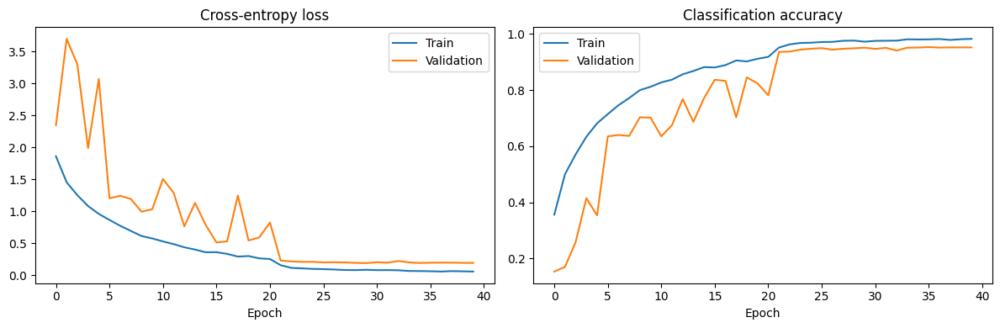

In [7]:
history_df = pd.read_csv(OUTPUT_DIR / 'training_history.csv')
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history_df['loss'], label='Train')
axs[0].plot(history_df['val_loss'], label='Validation')
axs[0].set_title('Cross-entropy loss')
axs[0].set_xlabel('Epoch')
axs[0].legend()
axs[1].plot(history_df['accuracy'], label='Train')
axs[1].plot(history_df['val_accuracy'], label='Validation')
axs[1].set_title('Classification accuracy')
axs[1].set_xlabel('Epoch')
axs[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=180)
plt.show()

## 8. Held-out test evaluation

2026-10-30 11:08:01.661547: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-30 11:08:01.796494: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793358483.626562      69 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

2026-10-30 11:08:15.136636: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-30 11:08:15.286200: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-30 11:08:15.420388: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


33/33 ━━━━━━━━━━━━━━━━━━━━ 27s 422ms/step
{
  "dataset": "Paddy Doctor: Paddy Disease Classification",
  "n_test": 1041,
  "accuracy": 0.9567723342939481,
  "balanced_accuracy": 0.9555482688581682,
  "macro_precision": 0.961343895397817,
  "macro_recall": 0.9555482688581682,
  "macro_f1": 0.9579942047644531,
  "weighted_f1": 0.9566440682117373,
  "num_parameters": 575058,
  "classes": [
    "bacterial_leaf_blight",
    "bacterial_leaf_streak",
    "bacterial_panicle_blight",
    "blast",
    "brown_spot",
    "dead_heart",
    "downy_mildew",
    "hispa",
    "normal",
    "tungro"
  ]
}


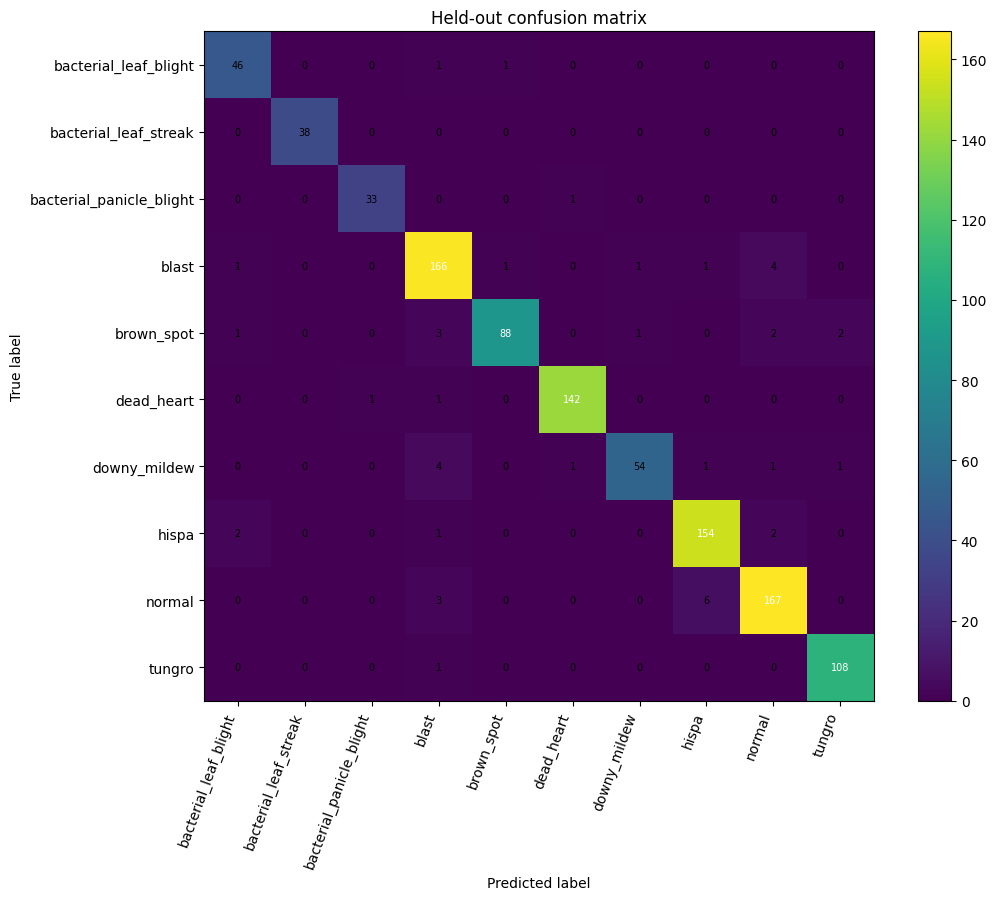

In [8]:
# Do not use the held-out split to tune hyperparameters.
# Only run this cell after final model and training configuration are frozen.
best_model = keras.models.load_model(str(BEST_MODEL), compile=False)
true_labels = test_frame['label_id'].to_numpy()
probabilities = best_model.predict(test_ds, verbose=1)
pred_labels = probabilities.argmax(axis=1)
report_dict = classification_report(
    true_labels, pred_labels, target_names=CLASS_NAMES,
    output_dict=True, zero_division=0
)
cm = confusion_matrix(true_labels, pred_labels, labels=list(range(len(CLASS_NAMES))))
metrics = {
    'dataset': 'Paddy Doctor: Paddy Disease Classification',
    'n_test': int(len(test_frame)),
    'accuracy': float(accuracy_score(true_labels, pred_labels)),
    'balanced_accuracy': float(balanced_accuracy_score(true_labels, pred_labels)),
    'macro_precision': float(report_dict['macro avg']['precision']),
    'macro_recall': float(report_dict['macro avg']['recall']),
    'macro_f1': float(report_dict['macro avg']['f1-score']),
    'weighted_f1': float(report_dict['weighted avg']['f1-score']),
    'num_parameters': int(best_model.count_params()),
    'classes': CLASS_NAMES,
}
print(json.dumps(metrics, indent=2))
(OUTPUT_DIR / 'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
pd.DataFrame(report_dict).T.to_csv(OUTPUT_DIR / 'classification_report.csv')
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    OUTPUT_DIR / 'confusion_matrix.csv')

pred_df = test_frame.copy()
pred_df['predicted_label_id'] = pred_labels
pred_df['predicted_class'] = [CLASS_NAMES[int(i)] for i in pred_labels]
pred_df['confidence'] = probabilities.max(axis=1)
for i, class_name in enumerate(CLASS_NAMES):
    pred_df[f'p_{class_name}'] = probabilities[:, i]
pred_df.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, interpolation='nearest')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=70, ha='right')
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Held-out confusion matrix')
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=180)
plt.show()

## 9. Export TensorFlow Lite model

In [9]:
# Float32 export is the reference. Quantization can be evaluated separately.
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    tflite_model = converter.convert()
    tflite_path = OUTPUT_DIR / 'lisa_paddy_fp32.tflite'
    tflite_path.write_bytes(tflite_model)
    print('TFLite saved:', tflite_path, f'({len(tflite_model):,} bytes)')
except Exception as exc:
    print('TFLite export was unsuccessful; the Keras checkpoint remains available.')
    print(type(exc).__name__, str(exc)[:500])

INFO:tensorflow:Assets written to: /tmp/tmp6phfvihf/assets


INFO:tensorflow:Assets written to: /tmp/tmp6phfvihf/assets


Saved artifact at '/tmp/tmp6phfvihf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133925975746576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975737360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975747920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975741584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975737552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975752528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133926204808592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133926204801680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975737936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925975750416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133925979801

W0000 00:00:1793358509.285053      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793358509.285082      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793358509.419177      23 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


## 10. Experiment metadata and result archive

In [10]:
configuration = {
    'dataset': 'paddy-disease-classification',
    'dataset_root': str(TRAIN_ROOT),
    'source_code': 'https://github.com/ZhijunBioinf/LiSA-MobileNetV2',
    'label_order': CLASS_NAMES,
    'seed': SEED,
    'image_size': list(IMAGE_SIZE),
    'global_batch_size': BATCH_SIZE,
    'strategy_replicas': strategy.num_replicas_in_sync,
    'max_epochs': MAX_EPOCHS,
    'optimizer': 'Adam',
    'learning_rate': LEARNING_RATE,
    'loss': 'categorical_crossentropy',
    'checkpoint_monitor': 'val_loss',
    'split': {'train': len(train_frame), 'val': len(val_frame), 'test': len(test_frame)},
    'tf_version': tf.__version__,
    'notes': 'Reimplementation of original LiSA architecture; paper split fractions; seed and TF augmentation implementation may differ. Competition test_images are unlabeled and unused.'
}
(OUTPUT_DIR / 'experiment_config.json').write_text(json.dumps(configuration, indent=2), encoding='utf-8')
import shutil
archive_path = shutil.make_archive('/kaggle/working/lisa_paddy_results', 'zip', OUTPUT_DIR)
print('Result archive:', archive_path)
print('All outputs:', sorted(p.name for p in OUTPUT_DIR.iterdir()))

Result archive: /kaggle/working/lisa_paddy_results.zip
All outputs: ['best_model.keras', 'class_names.json', 'classification_report.csv', 'confusion_matrix.csv', 'confusion_matrix.png', 'experiment_config.json', 'lisa_paddy_fp32.tflite', 'test_metrics.json', 'test_predictions.csv', 'test_split.csv', 'train_split.csv', 'training_curves.png', 'training_history.csv', 'val_split.csv']


## 11. Extended held-out test metrics (no retraining)

In [11]:
# This cell reads all previously saved predictions; no model loading is required.
# Do not use held-out test metrics for model selection or hyperparameter tuning.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve, log_loss, cohen_kappa_score,
    matthews_corrcoef, top_k_accuracy_score
)

OUT = Path('/kaggle/working/lisa_paddy_results')
pred_csv = OUT / 'test_predictions.csv'
if not pred_csv.exists():
    raise FileNotFoundError(f'{pred_csv} was not found. Run the original held-out test evaluation cell first.')

results = pd.read_csv(pred_csv)
if (OUT / 'class_names.json').exists():
    class_names = json.loads((OUT / 'class_names.json').read_text())
else:
    class_names = [c[2:] for c in results.columns if c.startswith('p_')]
prob_cols = [f'p_{name}' for name in class_names]
missing = set(['label_id', 'predicted_label_id', 'image_path', 'class_name', 'predicted_class'] + prob_cols) - set(results.columns)
if missing:
    raise KeyError(f'Missing columns in test_predictions.csv: {sorted(missing)}')

num_classes = len(class_names)
y_true = results['label_id'].to_numpy(dtype=np.int64)
y_pred = results['predicted_label_id'].to_numpy(dtype=np.int64)
probs = results[prob_cols].to_numpy(dtype=np.float64)
if not np.isfinite(probs).all() or (probs < 0).any():
    raise ValueError('Probability file contains non-finite or negative values.')
if not np.allclose(probs.sum(axis=1), 1.0, atol=1e-4):
    raise ValueError('Probabilities do not sum to one. Check the model outputs.')
probs = probs / probs.sum(axis=1, keepdims=True)
if not np.array_equal(y_pred, probs.argmax(axis=1)):
    raise ValueError('Predicted labels do not match the stored probabilities.')
if not all((0 <= y_true) & (y_true < num_classes)):
    raise ValueError('Invalid true class indices.')

labels = np.arange(num_classes)
y_one_hot = np.eye(num_classes, dtype=np.float64)[y_true]
confidence = probs.max(axis=1)
correct = y_true == y_pred
n = len(y_true)

def wilson_ci(successes, total, z=1.96):
    p = successes / total
    den = 1 + z*z/total
    center = (p + z*z/(2*total)) / den
    margin = z * np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / den
    return float(center-margin), float(center+margin)

def calibration_table(confidence_values, correctness, bins=15):
    indexes = np.digitize(confidence_values, np.linspace(0, 1, bins+1)[1:-1], right=True)
    rows = []
    for b in range(bins):
        mask = indexes == b
        rows.append({'bin': b+1, 'lower': b/bins, 'upper': (b+1)/bins,
                     'count': int(mask.sum()),
                     'mean_confidence': float(confidence_values[mask].mean()) if mask.any() else np.nan,
                     'accuracy': float(correctness[mask].mean()) if mask.any() else np.nan})
    return pd.DataFrame(rows)

calibration = calibration_table(confidence, correct)
ece = float(sum((int(r['count'])/n) * abs(float(r['accuracy']) - float(r['mean_confidence']))
                for _, r in calibration.iterrows() if r['count'] > 0))

p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
p_micro, r_micro, f_micro, _ = precision_recall_fscore_support(y_true, y_pred, average='micro', zero_division=0)
p_weight, r_weight, f_weight, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)

per_class_p, per_class_r, per_class_f, support = precision_recall_fscore_support(
    y_true, y_pred, labels=labels, zero_division=0
)
per_class_auc = []
per_class_ap = []
for c in labels:
    binary = (y_true == c).astype(int)
    per_class_auc.append(float(roc_auc_score(binary, probs[:, c])) if len(np.unique(binary)) == 2 else np.nan)
    per_class_ap.append(float(average_precision_score(binary, probs[:, c])) if binary.any() else np.nan)

# Unnormalized multiclass Brier score: mean over images of the sum across classes.
brier_multiclass = float(np.mean(np.sum((probs-y_one_hot)**2, axis=1)))
ci_lower, ci_upper = wilson_ci(int(correct.sum()), n)
summary = {
    'n_test': n, 'n_correct': int(correct.sum()), 'n_errors': int((~correct).sum()),
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'accuracy_95pct_wilson_ci': [ci_lower, ci_upper],
    'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
    'macro_precision': float(p_macro), 'macro_recall': float(r_macro), 'macro_f1': float(f_macro),
    'micro_precision': float(p_micro), 'micro_recall': float(r_micro), 'micro_f1': float(f_micro),
    'weighted_precision': float(p_weight), 'weighted_recall': float(r_weight), 'weighted_f1': float(f_weight),
    'top2_accuracy': float(top_k_accuracy_score(y_true, probs, k=2, labels=labels)),
    'top3_accuracy': float(top_k_accuracy_score(y_true, probs, k=3, labels=labels)),
    'top5_accuracy': float(top_k_accuracy_score(y_true, probs, k=5, labels=labels)),
    'roc_auc_ovr_macro': float(roc_auc_score(y_true, probs, labels=labels, multi_class='ovr', average='macro')),
    'roc_auc_ovr_weighted': float(roc_auc_score(y_true, probs, labels=labels, multi_class='ovr', average='weighted')),
    'mean_average_precision_ovr': float(np.nanmean(per_class_ap)),
    'negative_log_likelihood': float(log_loss(y_true, probs, labels=labels)),
    'multiclass_brier_score_unnormalized': brier_multiclass,
    'expected_calibration_error_15_bins': ece,
    'matthews_correlation_coefficient': float(matthews_corrcoef(y_true, y_pred)),
    'cohens_kappa': float(cohen_kappa_score(y_true, y_pred)),
    'mean_confidence_correct': float(confidence[correct].mean()) if correct.any() else None,
    'mean_confidence_incorrect': float(confidence[~correct].mean()) if (~correct).any() else None,
    'incorrect_with_confidence_ge_0_90': int(((~correct) & (confidence >= 0.90)).sum()),
}
per_class = pd.DataFrame({
    'class_name': class_names, 'support': support, 'precision': per_class_p,
    'recall': per_class_r, 'f1': per_class_f,
    'roc_auc_ovr': per_class_auc, 'average_precision_ovr': per_class_ap
}).sort_values('f1')
cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
confusions = sorted([
    {'true_class': class_names[i], 'predicted_class': class_names[j],
     'count': int(cm[i,j]), 'fraction_of_true_class': float(cm_norm[i,j])}
    for i in labels for j in labels if i != j and cm[i,j] > 0
], key=lambda row: -row['count'])

(OUT/'extended_test_metrics.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
per_class.to_csv(OUT/'extended_per_class_metrics.csv', index=False)
calibration.to_csv(OUT/'calibration_bins.csv', index=False)
pd.DataFrame(confusions).to_csv(OUT/'top_confusion_pairs.csv', index=False)
pd.DataFrame(cm_norm, index=class_names, columns=class_names).to_csv(OUT/'confusion_matrix_normalized.csv')
print('ALL HELD-OUT TEST METRICS')
print(pd.Series(summary).to_string())
print('\nPER-CLASS METRICS (weakest F1 first)')
print(per_class.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print('\nTOP CONFUSIONS')
print(pd.DataFrame(confusions).head(15).to_string(index=False))


ALL HELD-OUT TEST METRICS
n_test                                                                     1041
n_correct                                                                   996
n_errors                                                                     45
accuracy                                                               0.956772
accuracy_95pct_wilson_ci               [0.9426475668656525, 0.9675382450315767]
balanced_accuracy                                                      0.955548
macro_precision                                                        0.961344
macro_recall                                                           0.955548
macro_f1                                                               0.957994
micro_precision                                                        0.956772
micro_recall                                                           0.956772
micro_f1                                                               0.956772
weighted_preci

## 12. Test visualization: normalized confusion, ROC/PR and calibration

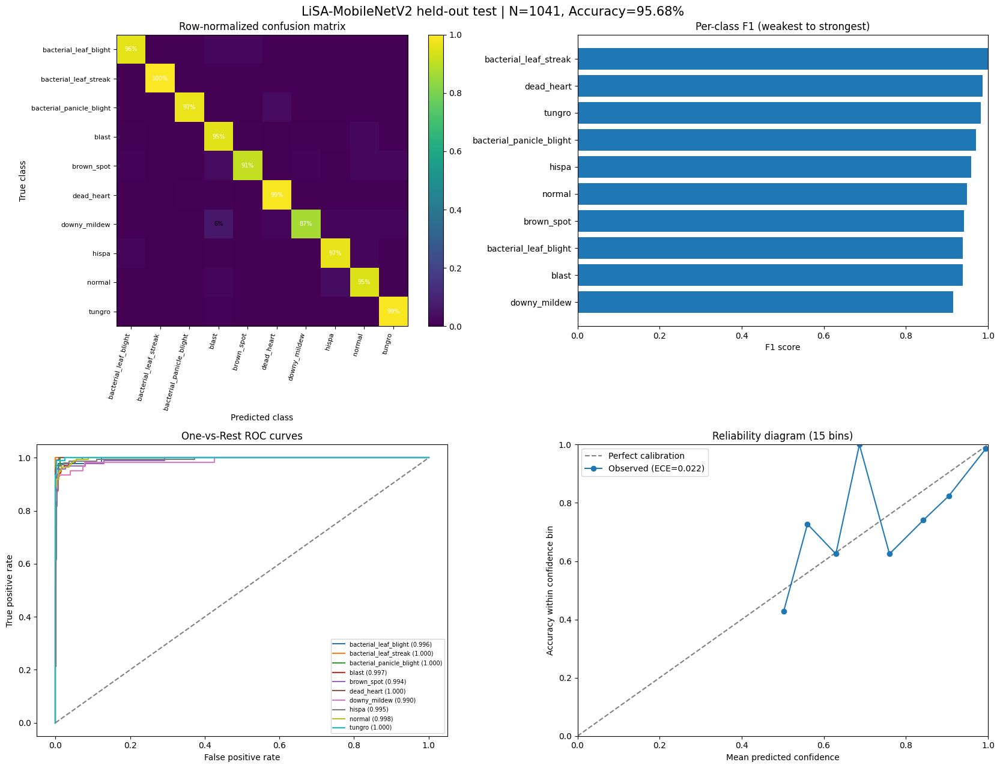

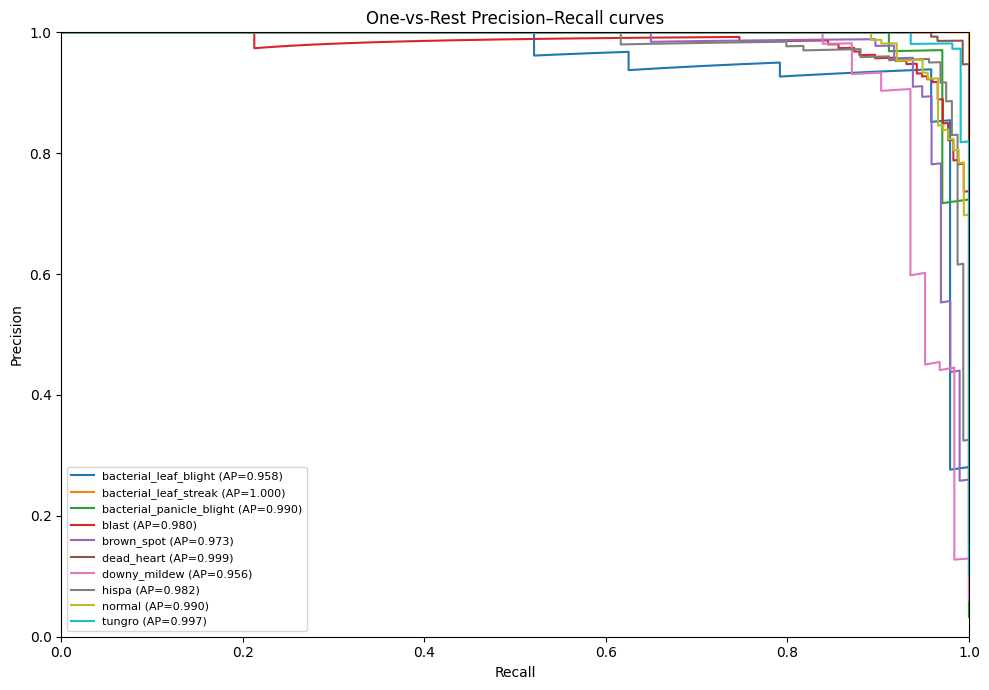

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(17, 13))

im = axs[0,0].imshow(cm_norm, vmin=0, vmax=1)
axs[0,0].set_xticks(labels, class_names, rotation=75, ha='right', fontsize=8)
axs[0,0].set_yticks(labels, class_names, fontsize=8)
axs[0,0].set_xlabel('Predicted class'); axs[0,0].set_ylabel('True class')
axs[0,0].set_title('Row-normalized confusion matrix')
for i in labels:
    for j in labels:
        if cm_norm[i,j] >= 0.035:
            axs[0,0].text(j, i, f'{cm_norm[i,j]:.0%}', ha='center', va='center', fontsize=7,
                          color='white' if cm_norm[i,j] >= 0.5 else 'black')
fig.colorbar(im, ax=axs[0,0], fraction=0.046)

per_class_plot = per_class.sort_values('f1')
axs[0,1].barh(per_class_plot['class_name'], per_class_plot['f1'])
axs[0,1].set_xlim(0, 1)
axs[0,1].set_xlabel('F1 score')
axs[0,1].set_title('Per-class F1 (weakest to strongest)')

for c, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve((y_true == c).astype(int), probs[:,c])
    axs[1,0].plot(fpr, tpr, label=f'{name} ({per_class_auc[c]:.3f})')
axs[1,0].plot([0,1], [0,1], linestyle='--', color='gray')
axs[1,0].set_xlabel('False positive rate'); axs[1,0].set_ylabel('True positive rate')
axs[1,0].set_title('One-vs-Rest ROC curves')
axs[1,0].legend(fontsize=7, loc='lower right')

nonempty_bins = calibration[calibration['count']>0]
axs[1,1].plot([0,1], [0,1], linestyle='--', color='gray', label='Perfect calibration')
axs[1,1].plot(nonempty_bins['mean_confidence'], nonempty_bins['accuracy'], 'o-',
              label=f'Observed (ECE={ece:.3f})')
axs[1,1].set_xlim(0,1); axs[1,1].set_ylim(0,1)
axs[1,1].set_xlabel('Mean predicted confidence')
axs[1,1].set_ylabel('Accuracy within confidence bin')
axs[1,1].set_title('Reliability diagram (15 bins)')
axs[1,1].legend()
fig.suptitle(f'LiSA-MobileNetV2 held-out test | N={n}, Accuracy={summary["accuracy"]:.2%}', fontsize=15)
fig.tight_layout()
fig.savefig(OUT/'extended_evaluation_overview.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10,7))
for c, name in enumerate(class_names):
    precision_curve, recall_curve, _ = precision_recall_curve((y_true == c).astype(int), probs[:,c])
    ax.plot(recall_curve, precision_curve, label=f'{name} (AP={per_class_ap[c]:.3f})')
ax.set(xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1),
       title='One-vs-Rest Precision–Recall curves')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT/'precision_recall_curves.png', dpi=180, bbox_inches='tight')
plt.show()


## 13. Failure cases: browse all errors and low-confidence correct images

all_errors: 45 images | Page 1/2 | Showing 24


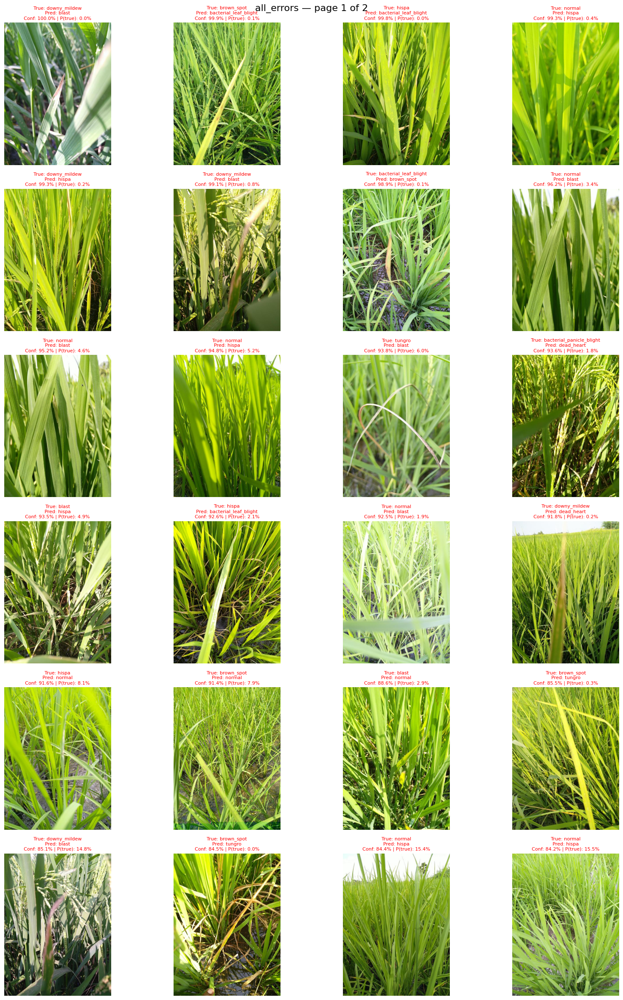


Top 10 overconfident errors:
                                                                                           image_path            class_name       predicted_class  confidence   p_true
         /kaggle/input/competitions/paddy-disease-classification/train_images/downy_mildew/109164.jpg          downy_mildew                 blast    0.999982 0.000017
           /kaggle/input/competitions/paddy-disease-classification/train_images/brown_spot/109750.jpg            brown_spot bacterial_leaf_blight    0.999234 0.000744
                /kaggle/input/competitions/paddy-disease-classification/train_images/hispa/102754.jpg                 hispa bacterial_leaf_blight    0.998145 0.000013
               /kaggle/input/competitions/paddy-disease-classification/train_images/normal/101029.jpg                normal                 hispa    0.993072 0.003866
         /kaggle/input/competitions/paddy-disease-classification/train_images/downy_mildew/102960.jpg          downy_mildew            

In [13]:
# Change MODE/PAGE and re-run this cell to browse as many test images as needed.
# MODE = 'all_errors' | 'high_confidence_errors' | 'low_confidence_correct'
MODE = 'all_errors'
PAGE = 0
PAGE_SIZE = 24                # 24 images per page; try 40 for a larger grid
SAVE_GALLERY = True

from PIL import Image
view = results.copy()
view['correct'] = correct
view['p_true'] = probs[np.arange(n), y_true]
view['confidence'] = confidence
view['error_margin'] = view['confidence'] - view['p_true']

if MODE == 'all_errors':
    selected = view[~view.correct].sort_values('confidence', ascending=False)
elif MODE == 'high_confidence_errors':
    selected = view[(~view.correct) & (view.confidence >= 0.90)].sort_values('confidence', ascending=False)
elif MODE == 'low_confidence_correct':
    selected = view[view.correct].sort_values('confidence', ascending=True)
else:
    raise ValueError(f'Unknown MODE: {MODE}')

num_pages = max(1, int(np.ceil(len(selected) / PAGE_SIZE)))
if PAGE >= num_pages or PAGE < 0:
    raise ValueError(f'PAGE must be in [0, {num_pages-1}].')
subset = selected.iloc[PAGE*PAGE_SIZE:(PAGE+1)*PAGE_SIZE]
print(f'{MODE}: {len(selected)} images | Page {PAGE+1}/{num_pages} | Showing {len(subset)}')

if len(subset) > 0:
    cols = 4
    rows = int(np.ceil(len(subset)/cols))
    fig, axs = plt.subplots(rows, cols, figsize=(17, rows * 4.0))
    axs = np.asarray(axs).reshape(-1)
    for ax, (_, sample) in zip(axs, subset.iterrows()):
        with Image.open(sample['image_path']) as img:
            ax.imshow(img.convert('RGB'))
        ax.set_title(f'True: {sample["class_name"]}\nPred: {sample["predicted_class"]}\n'
                     f'Conf: {sample["confidence"]:.1%} | P(true): {sample["p_true"]:.1%}',
                     color='green' if sample['correct'] else 'red', fontsize=8)
        ax.axis('off')
    for ax in axs[len(subset):]:
        ax.axis('off')
    fig.suptitle(f'{MODE} — page {PAGE+1} of {num_pages}', fontsize=16)
    fig.tight_layout()
    if SAVE_GALLERY:
        fig.savefig(OUT/f'{MODE}_page_{PAGE+1:02d}.png', dpi=160, bbox_inches='tight')
    plt.show()

# Select 10 high-confidence errors and print the true-label probability.
important = view[~view.correct].sort_values('confidence', ascending=False).head(10)
print('\nTop 10 overconfident errors:')
print(important[['image_path','class_name','predicted_class','confidence','p_true']].to_string(index=False))


## 14. Optional robustness stress tests (extra inference, no training)

clean              | Acc=95.68% | Macro-F1=0.9580
dim_0.7x           | Acc=29.39% | Macro-F1=0.2238
bright_1.3x        | Acc=45.53% | Macro-F1=0.3984
blur_3x3           | Acc=91.64% | Macro-F1=0.9157
down_up_112px      | Acc=87.51% | Macro-F1=0.8756


,variant,n,accuracy,macro_f1,balanced_accuracy,delta_accuracy_pp_vs_clean
0,clean,1041,0.956772,0.957994,0.955548,0.000000
1,dim_0.7x,1041,0.293948,0.223763,0.240254,-66.282421
2,bright_1.3x,1041,0.455331,0.398432,0.417389,-50.144092
3,blur_3x3,1041,0.916427,0.915655,0.910374,-4.034582
4,down_up_112px,1041,0.875120,0.875553,0.866279,-8.165226


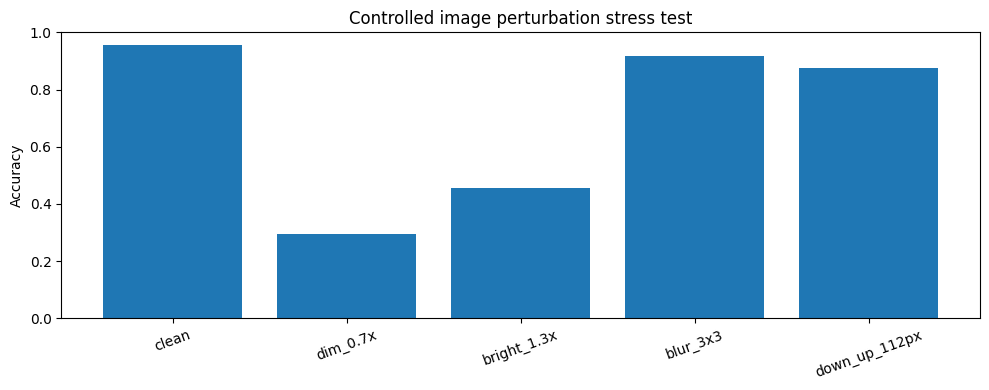

In [14]:
# Optional: re-evaluate the same held-out 1,041 images under controlled image perturbations.
# These are robustness diagnostics, not additional independent test samples.
# Avoid choosing or tuning the checkpoint based on this held-out test.
import tensorflow as tf
from tensorflow import keras

RUN_STRESS_TEST = True
if RUN_STRESS_TEST:
    checkpoint = OUT/'best_model.keras'
    if not checkpoint.exists():
        raise FileNotFoundError(f'Missing checkpoint {checkpoint}. Attach previous run outputs or rerun training.')
    stress_model = keras.models.load_model(checkpoint, compile=False)
    image_size=(224,224)

    def load_image(path, label, variant):
        raw = tf.io.read_file(path)
        img = tf.io.decode_image(raw, channels=3, expand_animations=False)
        img.set_shape((None,None,3))
        img = tf.image.resize(img, image_size)/255.0
        if variant == 'dim_0.7x':
            img = tf.clip_by_value(img*0.7,0,1)
        elif variant == 'bright_1.3x':
            img = tf.clip_by_value(img*1.3,0,1)
        elif variant == 'blur_3x3':
            img = tf.nn.avg_pool2d(img[None,...], 3, 1, 'SAME')[0]
        elif variant == 'down_up_112px':
            img = tf.image.resize(tf.image.resize(img,(112,112)), image_size)
        return img, label

    test_paths = results['image_path'].to_numpy(dtype=str)
    test_ids = results['label_id'].to_numpy(dtype=np.int32)
    variants = ['clean','dim_0.7x','bright_1.3x','blur_3x3','down_up_112px']
    stress_rows = []
    for variant in variants:
        dataset = tf.data.Dataset.from_tensor_slices((test_paths,test_ids))
        dataset = dataset.map(lambda x,y: load_image(x,y,variant),
                              num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(32).prefetch(tf.data.AUTOTUNE)
        stress_probs = stress_model.predict(dataset.map(lambda x,y:x),verbose=0)
        stress_pred = stress_probs.argmax(axis=1)
        _,_,macro_f1,_ = precision_recall_fscore_support(test_ids,stress_pred,average='macro',zero_division=0)
        stress_rows.append({'variant':variant,'n':len(test_ids),
                            'accuracy':accuracy_score(test_ids,stress_pred),
                            'macro_f1':macro_f1,'balanced_accuracy':balanced_accuracy_score(test_ids,stress_pred),
                            'delta_accuracy_pp_vs_clean':np.nan})
        print(f'{variant:18s} | Acc={stress_rows[-1]["accuracy"]:.2%} | Macro-F1={macro_f1:.4f}')
    stress_table = pd.DataFrame(stress_rows)
    stress_table['delta_accuracy_pp_vs_clean'] = 100*(stress_table['accuracy']-stress_table.loc[0,'accuracy'])
    stress_table.to_csv(OUT/'robustness_stress_test.csv',index=False)
    display(stress_table)
    fig,ax=plt.subplots(figsize=(10,4))
    ax.bar(stress_table['variant'],stress_table['accuracy'])
    ax.set(ylabel='Accuracy',title='Controlled image perturbation stress test',ylim=(0,1))
    ax.tick_params(axis='x',rotation=20)
    fig.tight_layout()
    fig.savefig(OUT/'robustness_stress_test.png',dpi=180,bbox_inches='tight')
    plt.show()


## 15. Optional: run predictions on Kaggle competition unlabeled test images (no accuracy available)

108/109 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step

2026-10-30 11:09:31.731368: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-30 11:09:31.871077: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


109/109 ━━━━━━━━━━━━━━━━━━━━ 23s 168ms/step
Unlabeled competition images scored: 3469
predicted_class
blast                       596
normal                      593
hispa                       525
dead_heart                  479
tungro                      363
brown_spot                  300
downy_mildew                194
bacterial_leaf_blight       176
bacterial_leaf_streak       127
bacterial_panicle_blight    116


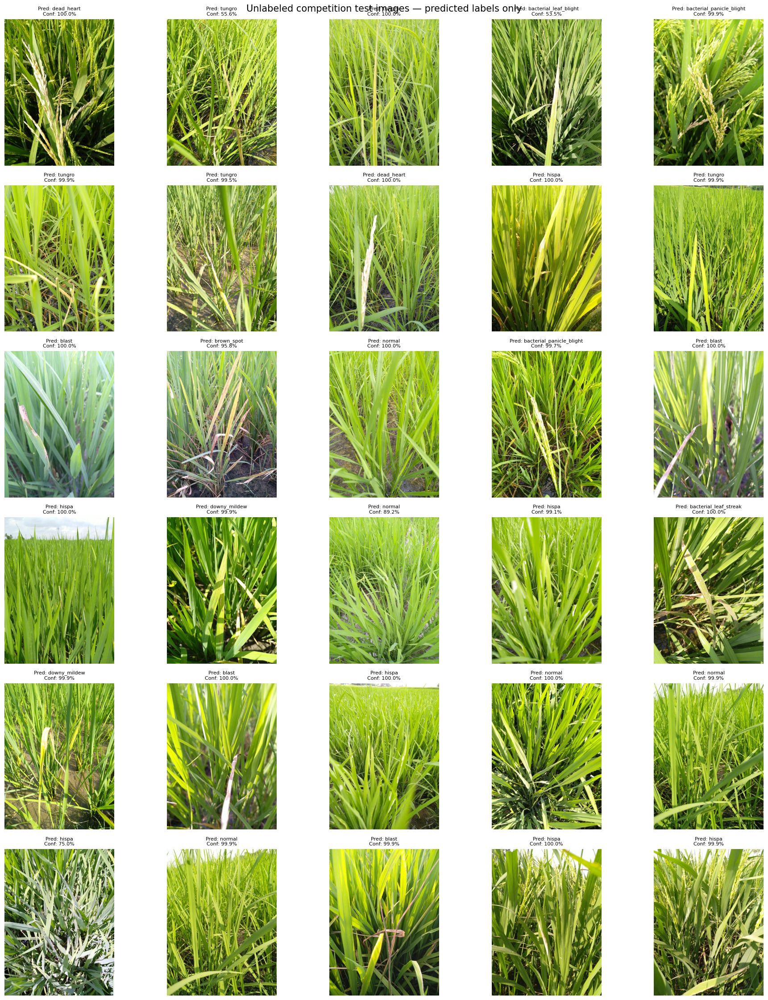

In [15]:
# Inference on 3,469 competition test images (if supplied by the competition mount).
# This adds images for qualitative review, but CANNOT provide accuracy/F1 without labels.
RUN_UNLABELED_COMPETITION_TEST = True
UNLABELED_GALLERY_N = 30
if RUN_UNLABELED_COMPETITION_TEST:
    test_root = Path(TRAIN_ROOT).parent / 'test_images'
    test_images = sorted(p for p in test_root.rglob('*')
                         if p.is_file() and p.suffix.lower() in ('.jpg','.jpeg','.png','.webp')) if test_root.exists() else []
    if not test_images:
        print('No unlabeled test_images found; skipping this optional section.')
    else:
        if not (OUT / 'best_model.keras').exists():
            raise FileNotFoundError('Saved best_model.keras is required to score competition images.')
        unlabeled_model = keras.models.load_model(OUT/'best_model.keras',compile=False)
        def decode_unlabeled(image_path):
            raw=tf.io.read_file(image_path)
            img=tf.io.decode_image(raw,channels=3,expand_animations=False)
            img.set_shape((None,None,3))
            return tf.image.resize(img,(224,224))/255.0
        ds=tf.data.Dataset.from_tensor_slices([str(p) for p in test_images])
        ds=ds.map(decode_unlabeled,num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE)
        pred_probs=unlabeled_model.predict(ds,verbose=1)
        chosen=pred_probs.argmax(axis=1)
        unlabeled_df=pd.DataFrame({'image_path':[str(p) for p in test_images],
                                   'predicted_label_id':chosen,
                                   'predicted_class':[class_names[i] for i in chosen],
                                   'confidence':pred_probs.max(axis=1)})
        for i,name in enumerate(class_names):
            unlabeled_df[f'p_{name}']=pred_probs[:,i]
        unlabeled_df.to_csv(OUT/'competition_unlabeled_predictions.csv',index=False)
        print(f'Unlabeled competition images scored: {len(unlabeled_df)}')
        print(unlabeled_df['predicted_class'].value_counts().to_string())
        examples=unlabeled_df.sample(min(UNLABELED_GALLERY_N,len(unlabeled_df)),random_state=42)
        cols=5;rows=int(np.ceil(len(examples)/cols))
        fig,axs=plt.subplots(rows,cols,figsize=(19,rows*3.8));axs=np.asarray(axs).reshape(-1)
        for ax,(_,r) in zip(axs,examples.iterrows()):
            with Image.open(r['image_path']) as img: ax.imshow(img.convert('RGB'))
            ax.set_title(f'Pred: {r["predicted_class"]}\nConf: {r["confidence"]:.1%}',fontsize=8)
            ax.axis('off')
        for ax in axs[len(examples):]: ax.axis('off')
        fig.suptitle('Unlabeled competition test images — predicted labels only',fontsize=15)
        fig.tight_layout()
        fig.savefig(OUT/'unlabeled_competition_gallery.png',dpi=160,bbox_inches='tight')
        plt.show()


## 16. Export extended evaluation artifacts

In [16]:
# Repackage all new plots, CSVs and JSON files into one ZIP after running the cells above.
import shutil
bundle = shutil.make_archive('/kaggle/working/lisa_paddy_extended_evaluation', 'zip', OUT)
print('Extended evaluation archive:', bundle)
print('New evaluation files:')
for p in sorted(OUT.iterdir()):
    if ('extended' in p.name or 'calibration' in p.name or 'robustness' in p.name or
        'confusion' in p.name or 'gallery' in p.name or 'precision_recall' in p.name or
        'errors' in p.name or 'competition_unlabeled' in p.name):
        print(' -', p.name)


Extended evaluation archive: /kaggle/working/lisa_paddy_extended_evaluation.zip
New evaluation files:
 - all_errors_page_01.png
 - calibration_bins.csv
 - competition_unlabeled_predictions.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - confusion_matrix_normalized.csv
 - extended_evaluation_overview.png
 - extended_per_class_metrics.csv
 - extended_test_metrics.json
 - precision_recall_curves.png
 - robustness_stress_test.csv
 - robustness_stress_test.png
 - top_confusion_pairs.csv
 - unlabeled_competition_gallery.png
